# Imaging with AIRI

This notebook reconstructs one monochromatic radio-interferometric image with AI for Regularization in Imaging, or `AIRI`. The example uses channel 2 of the {repo-tree}`simulated 3C 353 measurement data <data/3c353_sim_vla_meas_hs/>` included with the repository and launches pyHyperRI through the installed `hyri-imaging` command.

`AIRI` uses a trained denoising neural network as an image regulariser inside a forward-backward optimisation structure. In this tutorial, the packaged OAID denoiser shelf is used as specified in {repo-file}`config/tutorial.json <config/tutorial.json>`.


## What this notebook covers

By the end of the notebook, you should have seen how to:

- inspect the example measurement data and $uv$ coverage;
- select an AIRI denoiser shelf;
- run a single-channel AIRI reconstruction with `hyri-imaging`;
- load and visualise the main FITS outputs;
- calculate simple reconstruction metrics.


## RI imaging problem

The RI measurement process can be written as

$$
\boldsymbol{y} = \boldsymbol{\Phi}\bar{\boldsymbol{x}} + \boldsymbol{n},
$$

where $\boldsymbol{y}$ is the complex visibility vector, $\bar{\boldsymbol{x}}$ is the unknown sky image, $\boldsymbol{\Phi}$ is the measurement operator associated with incomplete Fourier sampling, and $\boldsymbol{n}$ is measurement noise.

AIRI reconstructs an image by alternating data-consistency steps with a learned denoising regulariser. The denoiser is selected from a shelf of ONNX networks according to the estimated image scale and noise level. In other words, the reconstruction aims to recover the image $\bar{\boldsymbol{x}}$ from the measurements $\boldsymbol{y}$.


## Setup

This notebook assumes it is run from `docs/tutorials/` and that pyHyperRI has already been installed, so `hyri-imaging` is available on the command line.

If pyHyperRI is not installed yet, follow the [Installation](../installation) guide first.


In [1]:
import subprocess
from pathlib import Path

from importlib import resources
import matplotlib.pyplot as plt
import numpy as np
import torch
from astropy.constants import c
from astropy.io import fits

from hyri.interface.io import load_mat_to_np

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
})

NOTEBOOK_DIR = Path.cwd()
ROOT = (NOTEBOOK_DIR / ".." / "..").resolve()
DATA_DIR = ROOT / "data" / "3c353_sim_vla_meas_hs"
CONFIG_PATH = ROOT / "config" / "tutorial.json"
RESULT_BASE = ROOT / "results" / "tutorials"
SRC_NAME = "airi_ch2"
RESULT_DIR = RESULT_BASE / SRC_NAME
DENOISER_SHELF = "shelf_airi_oaid.csv"

print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Repository root: {ROOT}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")

Notebook directory: /mnt/py-hyper-ri/docs/tutorials
Repository root: /mnt/py-hyper-ri
PyTorch: 2.10.0+cu128
CUDA available: True
CUDA device: NVIDIA A100-SXM4-40GB MIG 1g.5gb


## Inspect the example data

pyHyperRI expects a measurement directory containing one `msSpecs.mat` metadata file and one `data_ch_<index>.mat` file per physical channel. The tutorial configuration selects channel 2 only:

```json
{
    "ch_start": 2,
    "ch_last": 2,
    "ch_effective": 1
}
```

In [2]:
required_files = [
    CONFIG_PATH,
    DATA_DIR / "msSpecs.mat",
    DATA_DIR / "data_ch_2.mat",
    DATA_DIR / "groundtruth.fits",
]
missing = [path for path in required_files if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(str(path) for path in missing)
    )

for path in sorted(DATA_DIR.iterdir()):
    if path.suffix in {".mat", ".fits"}:
        print(path.relative_to(ROOT))

data/3c353_sim_vla_meas_hs/data_ch_1.mat
data/3c353_sim_vla_meas_hs/data_ch_2.mat
data/3c353_sim_vla_meas_hs/dirty_normalised.fits
data/3c353_sim_vla_meas_hs/groundtruth.fits
data/3c353_sim_vla_meas_hs/msSpecs.mat
data/3c353_sim_vla_meas_hs/psf.fits


The metadata file stores the sampling coordinates and channel frequencies. The per-channel file stores the measured visibilities and optional channel weights or flags. The following cell prints the available fields and their array shapes.

In [3]:
ms_specs = load_mat_to_np(str(DATA_DIR / "msSpecs.mat"))
meas_ch2 = load_mat_to_np(str(DATA_DIR / "data_ch_2.mat"))


def describe_fields(name, mapping):
    print(name)
    for key, value in sorted(mapping.items()):
        arr = np.asarray(value)
        if arr.shape == () or arr.size == 1:
            print(f"  {key}: scalar")
        else:
            print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")


describe_fields("msSpecs.mat", ms_specs)
describe_fields("data_ch_2.mat", meas_ch2)

msSpecs.mat
  freqs: shape=(1, 2), dtype=float64
  sigma: shape=(1, 2), dtype=float64
  tau: shape=(1, 2), dtype=float64
  uvw: shape=(3, 1652157), dtype=float64
data_ch_2.mat
  data_I: shape=(1, 1652157), dtype=complex128
  weightsImg: shape=(2,), dtype=uint64
  weightsNat: scalar


The 2D Fourier sampling pattern is usually called the $uv$ coverage. Here, the stored coordinates are converted from metres to wavelength units for channel 2 before plotting. The sampling pattern is scaled by a super-resolution factor of $1.5$, matching the imaging settings in {repo-file}`config/tutorial.json <config/tutorial.json>`.


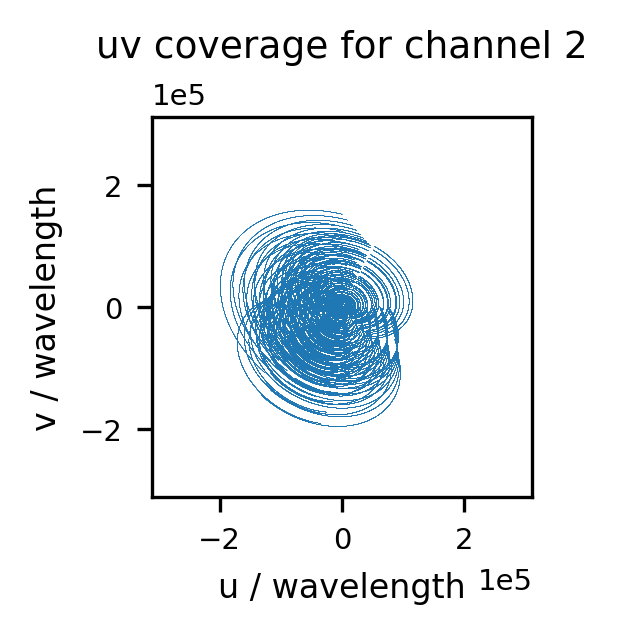

In [4]:
super_resolution = 1.5
freqs = np.asarray(ms_specs["freqs"]).squeeze()
freq_ch2 = float(freqs[1])
uvw_m = np.asarray(ms_specs["uvw"]).squeeze()

if uvw_m.shape[0] == 3:
    u_m, v_m = uvw_m[0], uvw_m[1]
else:
    u_m, v_m = uvw_m[:, 0], uvw_m[:, 1]

u = np.ravel(u_m) * freq_ch2 / c.value
v = np.ravel(v_m) * freq_ch2 / c.value
max_proj_baseline = np.max(np.sqrt(u**2 + v**2))
axis_limit = super_resolution * max_proj_baseline

fig, ax = plt.subplots(figsize=(2, 2), dpi=300, constrained_layout=True)
ax.scatter(
    u,
    v,
    s=0.1,
    alpha=0.5,
    marker=".",
    linewidths=0,
    rasterized=True,
)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-axis_limit, axis_limit)
ax.set_ylim(-axis_limit, axis_limit)
ax.ticklabel_format(style="sci", axis="both", scilimits=(0, 0))
ax.set_xlabel("u / wavelength")
ax.set_ylabel("v / wavelength")
ax.set_title("uv coverage for channel 2")
plt.show()


## AIRI denoiser shelf

The packaged AIRI shelves list ONNX denoisers trained for different noise levels. This tutorial uses the OAID shelf, `shelf_airi_oaid.csv`. The package also includes another shelf for AIRI, `shelf_airi_mrid.csv`. Each shelf CSV file has two columns. The first column gives the denoiser training noise level, and the second column gives the path to the corresponding ONNX file.


In [5]:
print(f"Denoiser shelf: {DENOISER_SHELF}")
package_denoiser_dir = resources.files("hyri").joinpath("airi_denoisers")
package_shelf_path = package_denoiser_dir.joinpath(DENOISER_SHELF)
if not package_shelf_path.is_file():
    raise FileNotFoundError(f"Denoiser shelf not found: {package_shelf_path}")

with package_shelf_path.open("r", encoding="utf-8") as f:
    print(f.read())

Denoiser shelf: shelf_airi_oaid.csv
2.5e-6,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_2.5e-6_seed_0.onnx
5.0e-6,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_5.0e-6_seed_0.onnx
1.0e-5,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_1.0e-5_seed_0.onnx
2.0e-5,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_2.0e-5_seed_0.onnx
4.0e-5,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_4.0e-5_seed_0.onnx
8.0e-5,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_8.0e-5_seed_0.onnx
1.6e-4,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_1.6e-4_seed_0.onnx
3.2e-4,v1_airi_astro-based_oaid_shelf/airi_oaid_dncnn_noise_3.2e-4_seed_0.onnx


A custom shelf can be used by creating a CSV file with the same structure and passing its path either in the JSON configuration file or as a command-line argument with `--dnn_shelf_path`.

## Run AIRI

The command below uses {repo-file}`config/tutorial.json <config/tutorial.json>` and overrides only the run-specific fields. The result path is set to `results/tutorials/airi_ch2/`.

In [6]:
cmd = [
    "hyri-imaging",
    "--config",
    str(CONFIG_PATH),
    "--algorithm",
    "airi",
    "--data_file",
    str(DATA_DIR),
    "--result_path",
    str(RESULT_BASE),
    "--src_name",
    SRC_NAME,
    "--dnn_shelf_path",
    DENOISER_SHELF,
]

print(" ".join(cmd))
subprocess.run(cmd, cwd=ROOT, check=True)

hyri-imaging --config /mnt/py-hyper-ri/config/tutorial.json --algorithm airi --data_file /mnt/py-hyper-ri/data/3c353_sim_vla_meas_hs --result_path /mnt/py-hyper-ri/results/tutorials --src_name airi_ch2 --dnn_shelf_path shelf_airi_oaid.csv
Input parameters
{
    "src_name": "airi_ch2",
    "data_file": "/mnt/py-hyper-ri/data/3c353_sim_vla_meas_hs",
    "result_path": "/mnt/py-hyper-ri/results/tutorials",
    "algorithm": "airi",
    "im_dim_x": 512,
    "im_dim_y": 512,
    "ch_start": 2,
    "ch_last": 2,
    "ch_effective": 1,
    "ch_partition": [],
    "im_pixel_size": [],
    "superresolution": 1.5,
    "groundtruth": [],
    "run_id": [],
    "flag_imaging": true,
    "flag_data_weighting": true,
    "invert_uvw_flag": false,
    "verbose": true,
    "weight_load": false,
    "weight_type": "briggs",
    "weight_robustness": 0,
    "weight_gridsize": 2,
    "meas_device": "cuda",
    "meas_dtype": "single",
    "regulariser_device": "cuda",
    "regulariser_dtype": "single",
    "

CompletedProcess(args=['hyri-imaging', '--config', '/mnt/py-hyper-ri/config/tutorial.json', '--algorithm', 'airi', '--data_file', '/mnt/py-hyper-ri/data/3c353_sim_vla_meas_hs', '--result_path', '/mnt/py-hyper-ri/results/tutorials', '--src_name', 'airi_ch2', '--dnn_shelf_path', 'shelf_airi_oaid.csv'], returncode=0)

## Load the outputs

The run writes the dirty image and PSF, followed by the final AIRI model and residual dirty image. The AIRI output prefix records the heuristic noise scale.

The expected FITS outputs are:

- `dirty.fits`: dirty image formed with the adjoint measurement operator.
- `psf.fits`: point spread function.
- `AIRI_heuScale_1.0_model_image.fits`: final reconstructed image.
- `AIRI_heuScale_1.0_residual_dirty_image.fits`: residual dirty image after reconstruction.


In [7]:
PREFIX = "AIRI_heuScale_1.0_"
output_files = {
    "psf": RESULT_DIR / "psf.fits",
    "dirty": RESULT_DIR / "dirty.fits",
    "model": RESULT_DIR / f"{PREFIX}model_image.fits",
    "residual": RESULT_DIR / f"{PREFIX}residual_dirty_image.fits",
}

groundtruth_path = DATA_DIR / "groundtruth.fits"
missing = [path for path in output_files.values() if not path.is_file()]
if not groundtruth_path.is_file():
    missing.append(groundtruth_path)
if missing:
    raise FileNotFoundError(
        "Missing output files: " + ", ".join(str(path) for path in missing)
    )


def read_image(path):
    return np.squeeze(fits.getdata(path).astype(float))


def read_groundtruth_channel_2(path):
    cube = np.squeeze(np.asarray(fits.getdata(path), dtype=float))
    if cube.ndim != 3 or cube.shape[0] < 2:
        raise ValueError(
            "Expected groundtruth.fits to be an image cube with at least two "
            f"channels, got shape {cube.shape}."
        )
    return cube[1]


images = {name: read_image(path) for name, path in output_files.items()}
images["groundtruth"] = read_groundtruth_channel_2(groundtruth_path)
for name, image in images.items():
    print(
        f"{name:8s} {image.shape} "
        f"min={np.nanmin(image):.3e} max={np.nanmax(image):.3e}"
    )

psf      (512, 512) min=-2.188e+03 max=1.244e+05
dirty    (512, 512) min=-2.868e+04 max=9.449e+05
model    (512, 512) min=0.000e+00 max=4.556e-01
residual (512, 512) min=-8.259e+02 max=6.999e+02
groundtruth (512, 512) min=0.000e+00 max=4.503e-01


## Visualise the PSF and dirty image

The PSF summarises the response of the measurement operator to a point source and is defined as $\boldsymbol{h} = \kappa\operatorname{Re}\{\boldsymbol{\Phi}^\dagger\boldsymbol{\Phi}\boldsymbol{\delta}\}$, where $\boldsymbol{\delta}$ is a Dirac image and $\kappa$ normalises the PSF peak to 1. The dirty image, or normalised back-projected data, is defined as $\boldsymbol{x}_d = \kappa\operatorname{Re}\{\boldsymbol{\Phi}^\dagger\boldsymbol{y}\}$. Both images are displayed in linear scale.


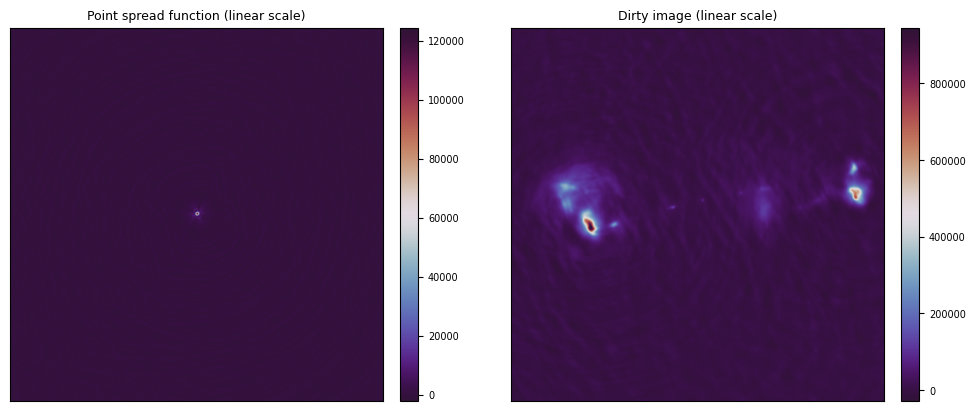

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

psf_artist = axes[0].imshow(images["psf"], origin="lower", cmap="twilight_shifted")
axes[0].set_title("Point spread function (linear scale)")
axes[0].set_xticks([])
axes[0].set_yticks([])
fig.colorbar(psf_artist, ax=axes[0], fraction=0.046, pad=0.04)

dirty_artist = axes[1].imshow(
    images["dirty"],
    origin="lower",
    cmap="twilight_shifted",
)
axes[1].set_title("Dirty image (linear scale)")
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(dirty_artist, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()


## Visualise the reconstruction

The reconstructed image is displayed in logarithmic scale using the mapping from the archived AIRI tutorial,

$$
\operatorname{rlog}(\boldsymbol{x}) = x_{\max} \log_a\left(\frac{a}{x_{\max}}\boldsymbol{x} + 1\right).
$$

The ground truth image is displayed with the same logarithmic mapping as the reconstructed image. The residual dirty image is displayed in linear scale and is defined as $\tilde{\boldsymbol{r}}=\operatorname{Re}\{\boldsymbol{\Phi}^\dagger(\boldsymbol{y}-\boldsymbol{\Phi}\tilde{\boldsymbol{x}})\}$.


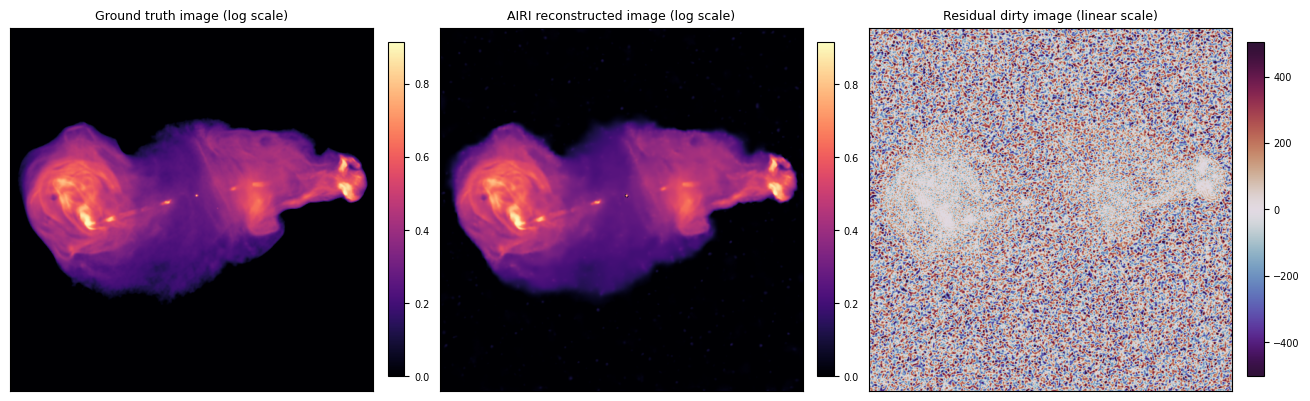

In [9]:
def rlog(x, a, x_max=1.0):
    return x_max * np.log10(a * x / x_max + 1.0) / np.log10(a)


dynamic_range = 1e4

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

groundtruth_artist = axes[0].imshow(
    rlog(np.clip(images["groundtruth"], 0.0, None), dynamic_range),
    origin="lower",
    cmap="magma",
)
axes[0].set_title("Ground truth image (log scale)")
axes[0].set_xticks([])
axes[0].set_yticks([])
fig.colorbar(groundtruth_artist, ax=axes[0], fraction=0.046, pad=0.04)

model_log = rlog(np.clip(images["model"], 0.0, None), dynamic_range)
model_artist = axes[1].imshow(
    model_log,
    origin="lower",
    cmap="magma",
)
axes[1].set_title("AIRI reconstructed image (log scale)")
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(model_artist, ax=axes[1], fraction=0.046, pad=0.04)

residual_limit = np.nanpercentile(np.abs(images["residual"]), 99.5)
residual_artist = axes[2].imshow(
    images["residual"],
    origin="lower",
    cmap="twilight_shifted",
    vmin=-residual_limit,
    vmax=residual_limit,
)
axes[2].set_title("Residual dirty image (linear scale)")
axes[2].set_xticks([])
axes[2].set_yticks([])
fig.colorbar(residual_artist, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()


## Calculate reconstruction metrics

The example `groundtruth.fits` file is an image cube with two channels. Since this tutorial reconstructs channel 2, the metrics below compare the AIRI model against the second ground-truth slice.

We use the SNR and logSNR metrics from the archived AIRI tutorial:

$$
\operatorname{SNR}(\bar{\boldsymbol{x}}, \tilde{\boldsymbol{x}}) = 20\log_{10}\left(\frac{\|\bar{\boldsymbol{x}}\|_2}{\|\bar{\boldsymbol{x}} - \tilde{\boldsymbol{x}}\|_2}\right),
$$

$$
\operatorname{logSNR}(\bar{\boldsymbol{x}}, \tilde{\boldsymbol{x}}) = \operatorname{SNR}(\operatorname{rlog}(\bar{\boldsymbol{x}}), \operatorname{rlog}(\tilde{\boldsymbol{x}})).
$$


In [10]:
def snr_rec(im_rec, im_true):
    numerator = np.linalg.norm(im_true.ravel())
    denominator = np.linalg.norm(im_true.ravel() - im_rec.ravel())
    return 20 * np.log10(numerator / denominator)


img_gdth = images["groundtruth"]
img_model = images["model"]

airi_snr = snr_rec(img_model, img_gdth)
airi_logsnr = snr_rec(
    rlog(np.clip(img_model, 0.0, None), dynamic_range),
    rlog(np.clip(img_gdth, 0.0, None), dynamic_range),
)
print(
    f"Reconstruction metrics: SNR {airi_snr:.3f} dB; "
    f"logSNR {airi_logsnr:.3f} dB"
)


Reconstruction metrics: SNR 32.306 dB; logSNR 26.588 dB


## References

- Terris, M., Dabbech, A., Tang, C., & Wiaux, Y. (2023).
  [Image reconstruction algorithms in radio interferometry: From handcrafted to
  learned regularization denoisers](https://doi.org/10.1093/mnras/stac2672).
  *MNRAS*, 518(1), 604-622.

- Terris, M., Tang, C., Jackson, A., & Wiaux, Y. (2025).
  [The AIRI plug-and-play algorithm for image reconstruction in
  radio-interferometry: variations and robustness](https://doi.org/10.1093/mnras/staf022).
  *MNRAS*, 537(2), 1608-1619.
